# Лабораторная работа-бонусное задание

**ФИО:** Ушакова Марина Михайловна  
**Группа:** ЕТ-212


1) Импорты и загрузка

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_excel('Iris.xlsx', sheet_name='Data')
df.head()

,Species_No,Petal_width,Petal_length,Sepal_width,Sepal_length,Species_name
0,1,0.2,1.4,3.5,5.1,Setosa
1,1,0.2,1.4,3.0,4.9,Setosa
2,1,0.2,1.3,3.2,4.7,Setosa
3,1,0.2,1.5,3.1,4.6,Setosa
4,1,0.2,1.4,3.6,5.0,Setosa


2) Удаление столбцов с сортом

In [2]:
df = df.drop(columns=['Species_No', 'Species_name'])
df.head()

,Petal_width,Petal_length,Sepal_width,Sepal_length
0,0.2,1.4,3.5,5.1
1,0.2,1.4,3.0,4.9
2,0.2,1.3,3.2,4.7
3,0.2,1.5,3.1,4.6
4,0.2,1.4,3.6,5.0


3) Переименование столбцов на русский

In [3]:
df = df.rename(columns={
    'Petal_width':  'ширина лепестка',
    'Petal_length': 'длина лепестка',
    'Sepal_width':  'ширина чашелистика',
    'Sepal_length': 'длина чашелистика',
})
df.head()

,ширина лепестка,длина лепестка,ширина чашелистика,длина чашелистика
0,0.2,1.4,3.5,5.1
1,0.2,1.4,3.0,4.9
2,0.2,1.3,3.2,4.7
3,0.2,1.5,3.1,4.6
4,0.2,1.4,3.6,5.0


4) Присвоить строкам индексы 1, 2, ….. 150.

In [4]:
df.index = range(1, len(df) + 1)
df.head()

,ширина лепестка,длина лепестка,ширина чашелистика,длина чашелистика
1,0.2,1.4,3.5,5.1
2,0.2,1.4,3.0,4.9
3,0.2,1.3,3.2,4.7
4,0.2,1.5,3.1,4.6
5,0.2,1.4,3.6,5.0


5) Создать функцию Gauss, которая “комплексно“ проверяет одномерную структуру на нормальность:

a.печатает объём выборки (shape?, len?)

b.строит гистограмму и/или kde

c.находит и распечатывает среднее и медиану (для нормально распределённых данных они должны быть близкими по значению)

d.находит и распечатывает асимметрию и эксцесс, используя функции /методы из Scipy (для нормально распределённых данных они должны быть близкими по значению к 0)

e.формулирует и распечатывает гипотезы Н0 и Н1.

f.вызывает функцию проверки на нормальность — критерий ХИ-квадрат Пирсона (библиотека Scipy).

g.распечатывает статистику ХИ-квадрат и p-значение, возвращаемые функцией

h.при уровне значимости α=0.05 осуществляет проверку гипотез и делает вывод, распределены ли данные нормально (по Гауссу)

In [10]:
def Gauss(series, name=''):
    x = series.dropna().values
    n = len(x)
    print(f"Показатель: {name}")

    print(f"Объём выборки: n = {n}")

    # гистограмма + kde
    plt.figure(figsize=(8, 4))
    sns.histplot(x, kde=True, stat='density', bins=15, color='steelblue')
    plt.title(f'Гистограмма и KDE: {name}')
    plt.xlabel(name)
    plt.ylabel('Плотность')
    plt.tight_layout()
    plt.show()

    # среднее и медиана
    mean = np.mean(x)
    median = np.median(x)
    print(f"Среднее: {mean:.4f}")
    print(f"Медиана: {median:.4f}")
    print(f"|Среднее - Медиана| = {abs(mean - median):.4f}")

    # асимметрия и эксцесс
    skew = stats.skew(x, bias=False)
    kurt = stats.kurtosis(x, bias=False)
    print(f"Асимметрия: {skew:.4f}")
    print(f"Эксцесс:    {kurt:.4f}")

    # гипотезы
    print("\nH0: данные распределены нормально")
    print("H1: данные НЕ распределены нормально")

    # хи-квадрат Пирсона
    mu, sigma = mean, np.std(x, ddof=1)
    bins = np.histogram_bin_edges(x, bins='auto')
    observed, _ = np.histogram(x, bins=bins)
    cdf_vals = stats.norm.cdf(bins, loc=mu, scale=sigma)
    expected = np.diff(cdf_vals) * n
    mask = expected > 0
    observed = observed[mask]
    expected = expected[mask]
    expected = expected * (observed.sum() / expected.sum())

    chi2_stat, p_value = stats.chisquare(f_obs=observed, f_exp=expected)

    print(f"\nСтатистика хи-квадрат: {chi2_stat:.4f}")
    print(f"p-значение:            {p_value:.6f}")

    alpha = 0.05
    print(f"\nα = {alpha}")
    if p_value < alpha:
        print("Вывод: p < α → H0 отвергается, данные НЕ нормальны.")
    else:
        print("Вывод: p ≥ α → H0 не отвергается, данные согласуются с нормальным.")

    return p_value

6) Проверка всех 4 показателей

Показатель: ширина лепестка
Объём выборки: n = 150


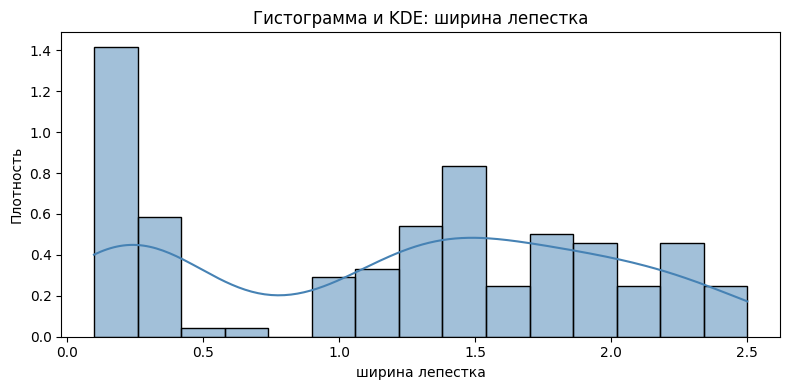

Среднее: 1.1993
Медиана: 1.3000
|Среднее - Медиана| = 0.1007
Асимметрия: -0.1030
Эксцесс:    -1.3406

H0: данные распределены нормально
H1: данные НЕ распределены нормально

Статистика хи-квадрат: 123.9775
p-значение:            0.000000

α = 0.05
Вывод: p < α → H0 отвергается, данные НЕ нормальны.
Показатель: длина лепестка
Объём выборки: n = 150


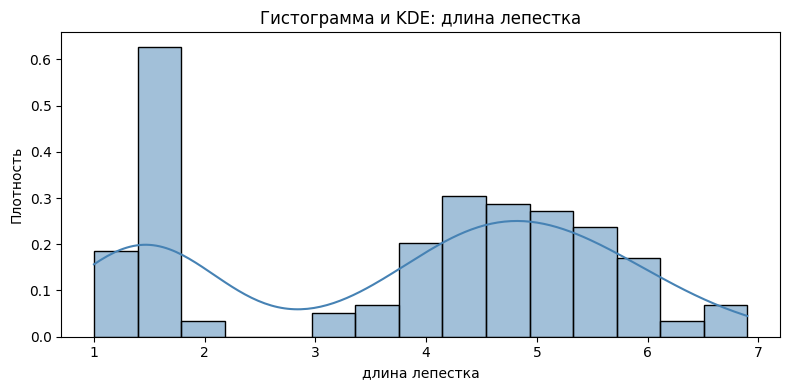

Среднее: 3.7580
Медиана: 4.3500
|Среднее - Медиана| = 0.5920
Асимметрия: -0.2749
Эксцесс:    -1.4021

H0: данные распределены нормально
H1: данные НЕ распределены нормально

Статистика хи-квадрат: 173.7158
p-значение:            0.000000

α = 0.05
Вывод: p < α → H0 отвергается, данные НЕ нормальны.
Показатель: ширина чашелистика
Объём выборки: n = 150


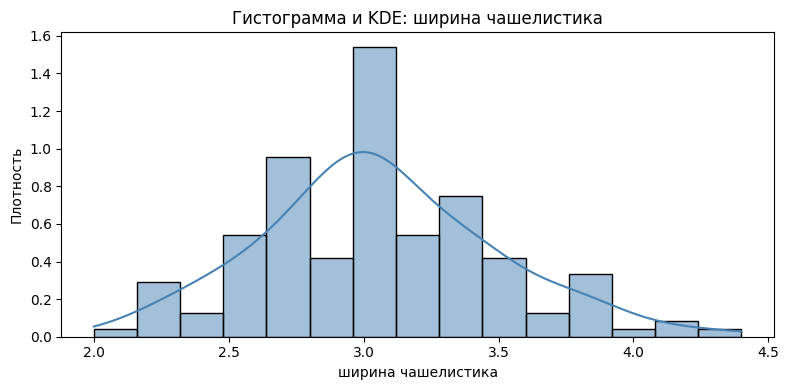

Среднее: 3.0573
Медиана: 3.0000
|Среднее - Медиана| = 0.0573
Асимметрия: 0.3190
Эксцесс:    0.2282

H0: данные распределены нормально
H1: данные НЕ распределены нормально

Статистика хи-квадрат: 14.6655
p-значение:            0.260243

α = 0.05
Вывод: p ≥ α → H0 не отвергается, данные согласуются с нормальным.
Показатель: длина чашелистика
Объём выборки: n = 150


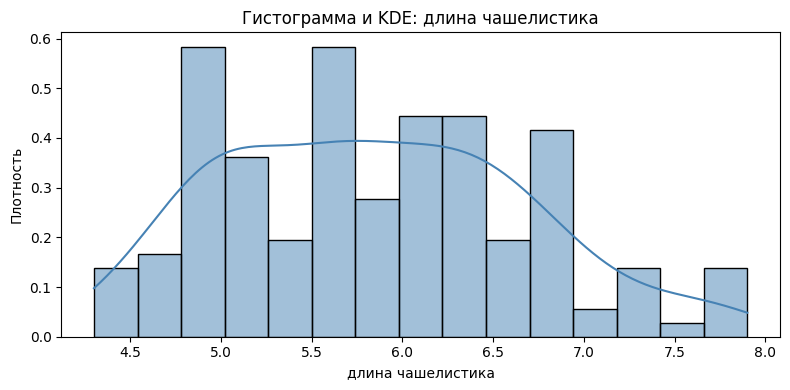

Среднее: 5.8433
Медиана: 5.8000
|Среднее - Медиана| = 0.0433
Асимметрия: 0.3149
Эксцесс:    -0.5521

H0: данные распределены нормально
H1: данные НЕ распределены нормально

Статистика хи-квадрат: 13.1093
p-значение:            0.108144

α = 0.05
Вывод: p ≥ α → H0 не отвергается, данные согласуются с нормальным.


In [11]:
p_values = {}
for col in df.columns:
    p_values[col] = Gauss(df[col], name=col)

7) Самый «ненормальный» показатель + по сортам


Самый «ненормальный» показатель: длина лепестка (p = 0.000000)

Показатель: длина лепестка — Setosa
Объём выборки: n = 50


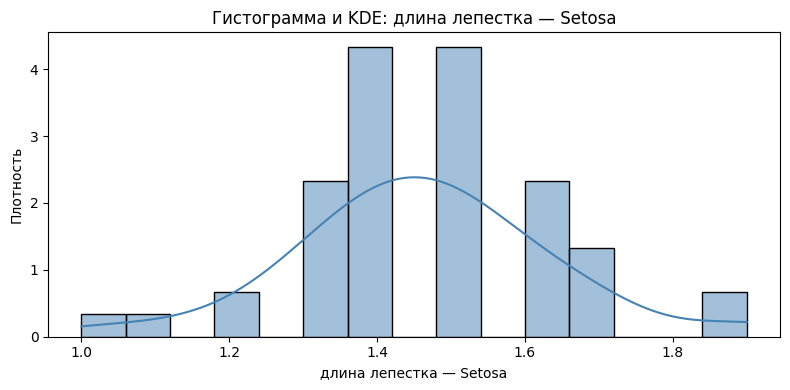

Среднее: 1.4620
Медиана: 1.5000
|Среднее - Медиана| = 0.0380
Асимметрия: 0.1064
Эксцесс:    1.0216

H0: данные распределены нормально
H1: данные НЕ распределены нормально

Статистика хи-квадрат: 7.8329
p-значение:            0.551073

α = 0.05
Вывод: p ≥ α → H0 не отвергается, данные согласуются с нормальным.

Показатель: длина лепестка — Versicolor
Объём выборки: n = 50


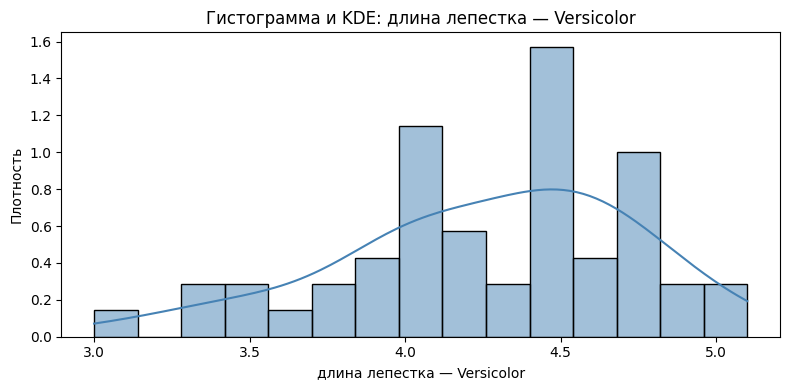

Среднее: 4.2600
Медиана: 4.3500
|Среднее - Медиана| = 0.0900
Асимметрия: -0.6065
Эксцесс:    0.0479

H0: данные распределены нормально
H1: данные НЕ распределены нормально

Статистика хи-квадрат: 7.3913
p-значение:            0.286168

α = 0.05
Вывод: p ≥ α → H0 не отвергается, данные согласуются с нормальным.

Показатель: длина лепестка — Verginica
Объём выборки: n = 50


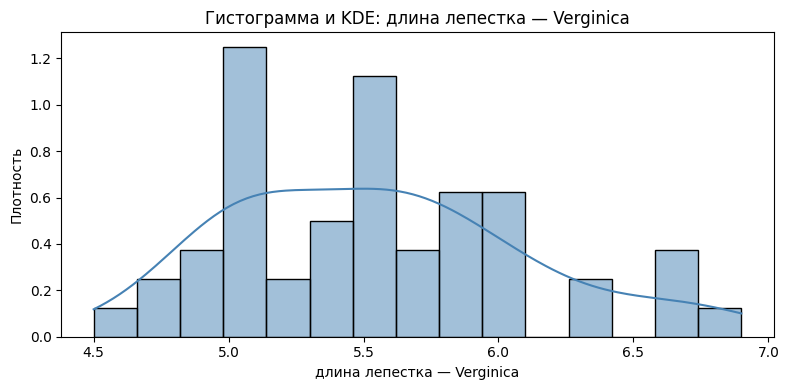

Среднее: 5.5520
Медиана: 5.5500
|Среднее - Медиана| = 0.0020
Асимметрия: 0.5494
Эксцесс:    -0.1538

H0: данные распределены нормально
H1: данные НЕ распределены нормально

Статистика хи-квадрат: 10.2697
p-значение:            0.113746

α = 0.05
Вывод: p ≥ α → H0 не отвергается, данные согласуются с нормальным.


In [9]:
# Находим самый ненормальный показатель
worst_col = min(p_values, key=p_values.get)
print(f"\nСамый «ненормальный» показатель: {worst_col} (p = {p_values[worst_col]:.6f})")

# Восстанавливаем исходный датафрейм для фильтрации по сортам
df_full = pd.read_excel('Iris.xlsx', sheet_name='Data')
df_full.index = range(1, len(df_full) + 1)
df_full = df_full.rename(columns={
    'Petal_width':  'ширина лепестка',
    'Petal_length': 'длина лепестка',
    'Sepal_width':  'ширина чашелистика',
    'Sepal_length': 'длина чашелистика',
})

# Сопоставление кодов сортов и названий
species_map = {1: 'Setosa', 2: 'Versicolor', 3: 'Verginica'}

for code, sp_name in species_map.items():
    subset = df_full.loc[df_full['Species_No'] == code, worst_col]
    Gauss(subset, name=f"{worst_col} — {sp_name}")

8) Для показателя, выбранного в пункте 7, проверить гипотезу о нормальном распределении отдельно для «мелких» цветков (это сорт setosa – 50 экземпляров) и «крупных» цветков (объединение двух других сортов – 100 экземпляров).

Показатель: длина лепестка — «мелкие» (Setosa)
Объём выборки: n = 50


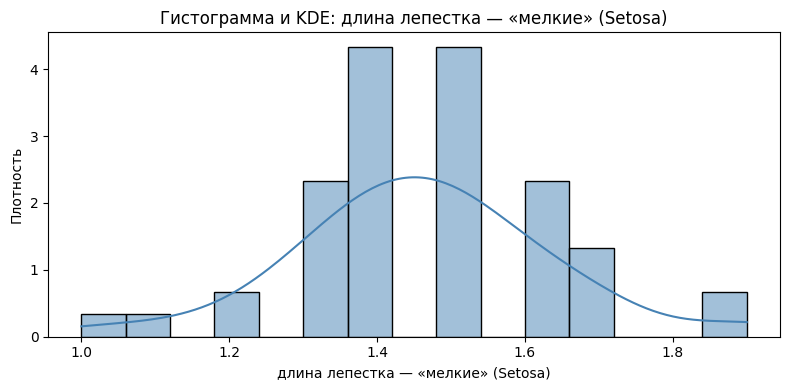

Среднее: 1.4620
Медиана: 1.5000
|Среднее - Медиана| = 0.0380
Асимметрия: 0.1064
Эксцесс:    1.0216

H0: данные распределены нормально
H1: данные НЕ распределены нормально

Статистика хи-квадрат: 7.8329
p-значение:            0.551073

α = 0.05
Вывод: p ≥ α → H0 не отвергается, данные согласуются с нормальным.
Показатель: длина лепестка — «крупные» (Versicolor+Verginica)
Объём выборки: n = 100


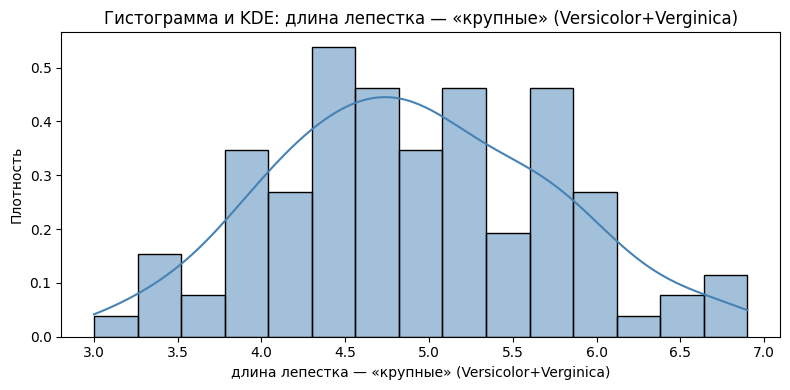

Среднее: 4.9060
Медиана: 4.9000
|Среднее - Медиана| = 0.0060
Асимметрия: 0.1711
Эксцесс:    -0.3248

H0: данные распределены нормально
H1: данные НЕ распределены нормально

Статистика хи-квадрат: 2.0640
p-значение:            0.956211

α = 0.05
Вывод: p ≥ α → H0 не отвергается, данные согласуются с нормальным.


np.float64(0.9562112672103378)

In [12]:
small = df_full.loc[df_full['Species_No'] == 1, worst_col]
large = df_full.loc[df_full['Species_No'].isin([2, 3]), worst_col]

Gauss(small, name=f"{worst_col} — «мелкие» (Setosa)")
Gauss(large, name=f"{worst_col} — «крупные» (Versicolor+Verginica)")

 ОБЩИЙ ВЫВОД:
Проверены 4 показателя критерием хи-квадрат Пирсона при α=0.05.

Самый «ненормальный» показатель проверен отдельно по сортам:
внутри одного сорта распределение ближе к нормальному,
чем в объединённой выборке (эффект смеси распределений).

Объединение Versicolor+Verginica даёт бимодальность/асимметрию
и сильнее нарушает нормальность.

Для параметрических методов лучше анализировать сорта по отдельности
или использовать непараметрические критерии